# Spatial view

This notebook maps KSI collisions in the Metropolitan Police area (DfT police-force code 1) for 2023-2025. The interactive heatmap uses a reproducible sample for speed; the static image summarizes all KSI records with valid coordinates.

Metropolitan Police area collisions: 64,266
Reported KSI collisions: 10,894
KSI collisions with valid coordinates: 10,894
Reported KSI rate in region: 16.95%
Interactive map uses 5,000 points: figures/metropolitan_police_ksi_heatmap.html


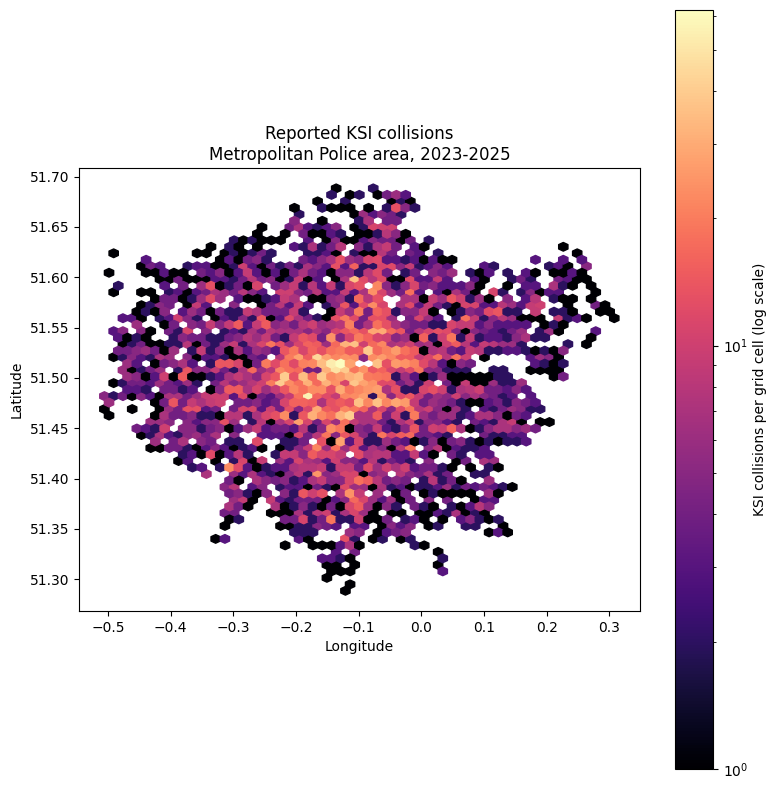

Static density image: figures/metropolitan_police_ksi_density.png


In [1]:
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from folium.plugins import HeatMap

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "collisions_clean.csv")
region = df.loc[df["police_force_code"].eq(1)].copy()
valid_coordinates = (
    region["latitude"].between(49, 61)
    & region["longitude"].between(-8, 2)
)
ksi_region = region.loc[region["ksi"].eq(1)].copy()
ksi_mapped = ksi_region.loc[valid_coordinates.loc[ksi_region.index]].copy()

print(f"Metropolitan Police area collisions: {len(region):,}")
print(f"Reported KSI collisions: {len(ksi_region):,}")
print(f"KSI collisions with valid coordinates: {len(ksi_mapped):,}")
print(f"Reported KSI rate in region: {region['ksi'].mean():.2%}")

map_points = ksi_mapped[["latitude", "longitude"]]
if len(map_points) > 5000:
    map_points = map_points.sample(n=5000, random_state=42)

center = [map_points["latitude"].median(), map_points["longitude"].median()]
crash_map = folium.Map(location=center, zoom_start=10, control_scale=True)
HeatMap(
    map_points.values.tolist(),
    radius=10,
    blur=14,
    min_opacity=0.25,
).add_to(crash_map)

FIGURE_DIR = PROJECT_ROOT / "figures"
html_path = FIGURE_DIR / "metropolitan_police_ksi_heatmap.html"
crash_map.save(html_path)
print(f"Interactive map uses {len(map_points):,} points: {html_path.relative_to(PROJECT_ROOT)}")

fig, axis = plt.subplots(figsize=(8, 8), facecolor="white")
hexes = axis.hexbin(
    ksi_mapped["longitude"],
    ksi_mapped["latitude"],
    gridsize=55,
    mincnt=1,
    bins="log",
    cmap="magma",
)
mean_latitude = ksi_mapped["latitude"].mean()
axis.set_aspect(1 / np.cos(np.deg2rad(mean_latitude)))
axis.set(
    title="Reported KSI collisions\nMetropolitan Police area, 2023-2025",
    xlabel="Longitude",
    ylabel="Latitude",
)
fig.colorbar(hexes, ax=axis, label="KSI collisions per grid cell (log scale)")
fig.tight_layout()
static_path = FIGURE_DIR / "metropolitan_police_ksi_density.png"
fig.savefig(static_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Static density image: {static_path.relative_to(PROJECT_ROOT)}")

## What the map can and cannot show

The heatmap shows where reported KSI collisions with usable coordinates cluster within the Metropolitan Police area. It is not a map of collision risk: there is no traffic-volume or road-use exposure denominator, overlapping points are aggregated, and police-reported slight collisions may be under-recorded. The force boundary is also not identical to the Greater London administrative boundary.